## 1. Setup and load data

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/domestic-flight-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv


In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import KFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

DATA_DIR = "/kaggle/input/competitions/domestic-flight-price-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample.shape)

display(train.head())
display(test.head())
display(sample.head())

Train: (15589, 12)
Test: (3898, 11)
Sample submission: (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,1,NaN,6E 6017,Springfield,Evening,one,Night,Hill Valley,Economy,5.25,23
1,2,Wayfarer Aviation,AI 2951,Metropolis,Afternoon,zero,Afternoon,Night City,Economy,2.33,46
2,3,Oceanic Airlines,6E 6140,Gotham,Late_Night,one,Early_Morning,Los Santos,Business,4.83,16
3,4,Oceanic Airlines,6E 495,Gotham,Early_Morning,one,Afternoon,Metropolis,Business,5.33,7
4,5,Oceanic Airlines,6E 796,Gotham,Night,zero,Night,Springfield,Economy,1.00,19


,id,price
0,1,0.0
1,2,0.0
2,3,0.0
3,4,0.0
4,5,0.0


In [3]:
print("Training columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

print("\nMissing values in training data:")
display(train.isna().sum().sort_values(ascending=False))

print("\nMissing values in test data:")
display(test.isna().sum().sort_values(ascending=False))

assert "price" in train.columns
assert "price" not in test.columns
assert "id" in test.columns
assert list(sample.columns) == ["id", "price"]

Training columns:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price']

Test columns:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']

Missing values in training data:


duration            3095
airline             3089
flight                 0
id                     0
source_city            0
departure_time         0
arrival_time           0
stops                  0
destination_city       0
flight_class           0
days_left              0
price                  0
dtype: int64


Missing values in test data:


airline             799
duration            776
id                    0
flight                0
source_city           0
stops                 0
departure_time        0
arrival_time          0
destination_city      0
flight_class          0
days_left             0
dtype: int64

## 2. Feature engineering

In [4]:
# Preserve the original target and IDs
y = train["price"].astype(float).copy()
train_ids = train["id"].copy()
test_ids = test["id"].copy()

# Combine features only; never include price in the combined data
train_features = train.drop(columns=["price", "id"]).copy()
test_features = test.drop(columns=["id"]).copy()

n_train = len(train_features)
full = pd.concat(
    [train_features, test_features],
    ignore_index=True
)

# Extract airline code and flight number
flight_parts = full["flight"].astype("string").str.extract(
    r"^\s*(\S+)\s+(\d+)\s*$"
)

full["airline_code"] = flight_parts[0].fillna("UNKNOWN")
full["flight_num"] = pd.to_numeric(
    flight_parts[1], errors="coerce"
)

# Recover missing airline using the observed airline-code mapping
airline_map = (
    full.dropna(subset=["airline"])
        .groupby("airline_code")["airline"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
)

full["airline"] = full["airline"].fillna(
    full["airline_code"].map(airline_map)
)

full["airline"] = full["airline"].fillna("Unknown")

# Create route feature
full["route"] = (
    full["source_city"].astype(str)
    + ">"
    + full["destination_city"].astype(str)
)

# Convert duration to numeric if necessary
full["duration"] = pd.to_numeric(
    full["duration"], errors="coerce"
)

# Impute missing duration from progressively broader groups
for cols in [
    ["flight", "route", "stops"],
    ["route", "stops", "departure_time"],
    ["route", "stops"],
    ["route"]
]:
    group_median = full.groupby(
        cols, dropna=False
    )["duration"].transform("median")

    full["duration"] = full["duration"].fillna(group_median)

full["duration"] = full["duration"].fillna(
    full["duration"].median()
)

# Encode stops as an ordinal feature
stop_map = {
    "zero": 0,
    "one": 1,
    "two_or_more": 2
}

full["stops_n"] = full["stops"].map(stop_map).fillna(-1)

# Time categories
time_map = {
    "Early_Morning": 0,
    "Morning": 1,
    "Afternoon": 2,
    "Evening": 3,
    "Night": 4,
    "Late_Night": 5
}

full["dep_t"] = full["departure_time"].map(time_map).fillna(-1)
full["arr_t"] = full["arrival_time"].map(time_map).fillna(-1)

# Business-class indicator and interaction
full["is_biz"] = (full["flight_class"] == "Business").astype(int)
full["biz_x_dur"] = full["is_biz"] * full["duration"]

# Days remaining features
full["days_left"] = pd.to_numeric(
    full["days_left"], errors="coerce"
)

full["log_days"] = np.log1p(
    full["days_left"].clip(lower=0)
)

full["days_bucket"] = pd.cut(
    full["days_left"],
    bins=[-1, 1, 2, 7, 14, 21, 30, 60, np.inf],
    labels=False
).fillna(-1).astype(int)

# Useful categorical interactions
full["airline_class"] = (
    full["airline"].astype(str)
    + "_"
    + full["flight_class"].astype(str)
)

full["route_class"] = (
    full["route"].astype(str)
    + "_"
    + full["flight_class"].astype(str)
)

# Remove the original flight string; extracted features are retained
full = full.drop(columns=["flight"])

# Split back into train and test
X_train = full.iloc[:n_train].copy().reset_index(drop=True)
X_test = full.iloc[n_train:].copy().reset_index(drop=True)

# Categorical columns for LightGBM
cat_cols = [
    "airline",
    "airline_code",
    "source_city",
    "destination_city",
    "route",
    "departure_time",
    "arrival_time",
    "stops",
    "flight_class",
    "airline_class",
    "route_class"
]

# Use identical category definitions in train and test
for col in cat_cols:
    categories = full[col].astype("string").fillna("Unknown").unique()

    X_train[col] = pd.Categorical(
        X_train[col].astype("string").fillna("Unknown"),
        categories=categories
    )

    X_test[col] = pd.Categorical(
        X_test[col].astype("string").fillna("Unknown"),
        categories=categories
    )

# Check the final matrices
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Missing duration:", X_train["duration"].isna().sum(),
      X_test["duration"].isna().sum())

display(X_train.head())

X_train: (15589, 21)
X_test: (3898, 21)
Missing duration: 0 0


,airline,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,airline_code,...,route,stops_n,dep_t,arr_t,is_biz,biz_x_dur,log_days,days_bucket,airline_class,route_class
0,Wayfarer Aviation,Metropolis,Evening,zero,Night,Springfield,Economy,2.92,18,IX,...,Metropolis>Springfield,0,3,4,0,0.00,2.944439,4,Wayfarer Aviation_Economy,Metropolis>Springfield_Economy
1,Oceanic Airlines,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,6E,...,Los Santos>Springfield,0,4,4,0,0.00,3.663562,6,Oceanic Airlines_Economy,Los Santos>Springfield_Economy
2,Wayfarer Aviation,Night City,Evening,zero,Night,Springfield,Business,2.08,13,AI,...,Night City>Springfield,0,3,4,1,2.08,2.639057,3,Wayfarer Aviation_Business,Night City>Springfield_Business
3,Oceanic Airlines,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6E,...,Night City>Metropolis,0,2,3,0,0.00,1.791759,2,Oceanic Airlines_Economy,Night City>Metropolis_Economy
4,Oceanic Airlines,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6E,...,Hill Valley>Springfield,1,3,4,0,0.00,3.091042,4,Oceanic Airlines_Economy,Hill Valley>Springfield_Economy


## 3. Baseline: Decision Tree (defines `X`, `target`, `preprocessor`, `oof`)

In [5]:

from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

X = X_train.copy()
target = np.asarray(y, dtype=float)

# Identify categorical and numerical columns
cat_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

num_features = X.select_dtypes(
    include=[np.number]
).columns.tolist()

# Preprocessing: fill missing values and encode categories
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])

# 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof = np.zeros(len(X))

for fold, (tr, val) in enumerate(kf.split(X), 1):
    model = Pipeline([
        ("prep", preprocessor),
        ("tree", DecisionTreeRegressor(
            max_depth=20,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ])

    model.fit(X.iloc[tr], target[tr])
    oof[val] = model.predict(X.iloc[val])

    print(f"Fold {fold} completed")

rmse = np.sqrt(mean_squared_error(target, oof))
mae = mean_absolute_error(target, oof)

print("\nDecision Tree Results")
print("RMSE:", round(rmse, 2))
print("MAE :", round(mae, 2))


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Decision Tree Results
RMSE: 12311.92
MAE : 3920.07


## 4. Polynomial Ridge

In [6]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Use numerical features only for this experiment
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

# Limit to a manageable number of numerical features
Xp = X[num_cols].copy()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_poly = np.zeros(len(Xp))

for fold, (tr, val) in enumerate(kf.split(Xp), 1):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("ridge", Ridge(alpha=10))
    ])

    model.fit(Xp.iloc[tr], target[tr])
    oof_poly[val] = model.predict(Xp.iloc[val])

    print(f"Fold {fold} completed")

print("\nPolynomial Ridge Results")
print("RMSE:", round(np.sqrt(mean_squared_error(target, oof_poly)), 2))
print("MAE :", round(mean_absolute_error(target, oof_poly), 2))


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Polynomial Ridge Results
RMSE: 17305.31
MAE : 7769.22


## 5. Decision Tree + Polynomial blend

In [7]:

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Try different weights for Decision Tree
for w in [0.25, 0.50, 0.75, 0.90]:
    ensemble_pred = w * oof + (1 - w) * oof_poly

    rmse = np.sqrt(mean_squared_error(target, ensemble_pred))
    mae = mean_absolute_error(target, ensemble_pred)

    print(
        f"Decision Tree weight={w:.2f}, "
        f"Polynomial weight={1-w:.2f} | "
        f"RMSE={rmse:.2f}, MAE={mae:.2f}"
    )


Decision Tree weight=0.25, Polynomial weight=0.75 | RMSE=14799.21, MAE=6396.98
Decision Tree weight=0.50, Polynomial weight=0.50 | RMSE=12944.08, MAE=5228.10
Decision Tree weight=0.75, Polynomial weight=0.25 | RMSE=12044.56, MAE=4335.00
Decision Tree weight=0.90, Polynomial weight=0.10 | RMSE=12062.33, MAE=3991.48


## 6. Random Forest (defines `oof_rf`)

In [8]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_rf = np.zeros(len(X))

for fold, (tr, val) in enumerate(kf.split(X), 1):
    model = Pipeline([
        ("prep", clone(preprocessor)),
        ("rf", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=2,
            max_features=0.8,
            n_jobs=-1,
            random_state=42
        ))
    ])

    model.fit(X.iloc[tr], target[tr])
    oof_rf[val] = model.predict(X.iloc[val])

    print(f"Fold {fold} completed")

print("\nRandom Forest Results")
print("RMSE:", round(np.sqrt(mean_squared_error(target, oof_rf)), 2))
print("MAE :", round(mean_absolute_error(target, oof_rf), 2))


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Random Forest Results
RMSE: 10638.89
MAE : 3378.21


## 7. LightGBM

In [9]:
def build_model():
    return lgb.LGBMRegressor(
        objective="regression",
        n_estimators=1200,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=15,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

print("LightGBM model is ready.")

LightGBM model is ready.


In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_predictions = {
    "raw": np.zeros(len(y)),
    "log": np.zeros(len(y))
}

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_train), start=1):
    print(f"\n========== Fold {fold}/5 ==========")

    for target_name in ["raw", "log"]:
        model = build_model()

        y_fit = (
            np.log(y.iloc[train_idx])
            if target_name == "log"
            else y.iloc[train_idx]
        )

        model.fit(
            X_train.iloc[train_idx],
            y_fit,
            categorical_feature=cat_cols
        )

        pred = model.predict(X_train.iloc[valid_idx])

        if target_name == "log":
            pred = np.exp(pred)

        pred = np.clip(pred, 0, None)
        oof_predictions[target_name][valid_idx] = pred

        rmse = np.sqrt(
            mean_squared_error(y.iloc[valid_idx], pred)
        )

        print(f"{target_name.upper()} price RMSE: {rmse:.2f}")

# Compare full out-of-fold predictions
results = []

for name, pred in oof_predictions.items():
    results.append({
        "target": name,
        "R2": r2_score(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "MAE": mean_absolute_error(y, pred),
        "MAPE_percent": (
            np.mean(np.abs(pred - y.to_numpy()) /
                    np.maximum(np.abs(y.to_numpy()), 1e-8)) * 100
        )
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df.round(4))

best_target = results_df.iloc[0]["target"]
print("Best target transformation:", best_target)


========== Fold 1/5 ==========
RAW price RMSE: 10407.69
LOG price RMSE: 10009.69

========== Fold 2/5 ==========
RAW price RMSE: 10204.27
LOG price RMSE: 10331.43

========== Fold 3/5 ==========
RAW price RMSE: 10832.54
LOG price RMSE: 10687.02

========== Fold 4/5 ==========
RAW price RMSE: 10895.61
LOG price RMSE: 10930.31

========== Fold 5/5 ==========
RAW price RMSE: 10471.71
LOG price RMSE: 9936.91


,target,R2,RMSE,MAE,MAPE_percent
1,log,0.9295,10386.1593,3327.0204,7.7360
0,raw,0.9271,10565.6310,3652.2407,10.0811


Best target transformation: log


## 8. Random Forest + LightGBM blend

In [11]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Actual prices
actual = y.to_numpy()

# Out-of-fold predictions from both models
rf_pred = np.asarray(oof_rf)
lgb_pred = np.asarray(oof_predictions["log"])

# Verify prediction arrays
assert len(actual) == len(rf_pred) == len(lgb_pred), \
    "Prediction arrays have different lengths!"

print("Random Forest + LightGBM Ensemble")
print("-" * 55)

best_rmse = float("inf")
best_weight = None

# Try different combinations
for w in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:

    # w = Random Forest weight
    # (1-w) = LightGBM weight
    pred = w * rf_pred + (1 - w) * lgb_pred

    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)

    print(
        f"RF={w:.0%}, LightGBM={1-w:.0%} | "
        f"RMSE={rmse:.2f}, MAE={mae:.2f}"
    )

    if rmse < best_rmse:
        best_rmse = rmse
        best_weight = w

print("\nBest ensemble weights:")
print(f"Random Forest: {best_weight:.0%}")
print(f"LightGBM: {1-best_weight:.0%}")
print(f"Best OOF RMSE: {best_rmse:.2f}")

Random Forest + LightGBM Ensemble
-------------------------------------------------------
RF=0%, LightGBM=100% | RMSE=10386.16, MAE=3327.02
RF=10%, LightGBM=90% | RMSE=10318.59, MAE=3303.85
RF=20%, LightGBM=80% | RMSE=10271.48, MAE=3286.01
RF=30%, LightGBM=70% | RMSE=10245.10, MAE=3274.52
RF=40%, LightGBM=60% | RMSE=10239.63, MAE=3269.56
RF=50%, LightGBM=50% | RMSE=10255.09, MAE=3271.22
RF=60%, LightGBM=40% | RMSE=10291.39, MAE=3278.91
RF=70%, LightGBM=30% | RMSE=10348.32, MAE=3293.95
RF=80%, LightGBM=20% | RMSE=10425.52, MAE=3315.41
RF=90%, LightGBM=10% | RMSE=10522.56, MAE=3343.49
RF=100%, LightGBM=0% | RMSE=10638.89, MAE=3378.21

Best ensemble weights:
Random Forest: 40%
LightGBM: 60%
Best OOF RMSE: 10239.63


## 9. Final model and submission

In [12]:
final_model = build_model()

y_final = np.log(y) if best_target == "log" else y

final_model.fit(
    X_train,
    y_final,
    categorical_feature=cat_cols
)

test_predictions = final_model.predict(X_test)

if best_target == "log":
    test_predictions = np.exp(test_predictions)

test_predictions = np.clip(test_predictions, 0, None)

print("Predictions generated:", len(test_predictions))
print("Minimum predicted price:", test_predictions.min())
print("Maximum predicted price:", test_predictions.max())
print("Missing predictions:", np.isnan(test_predictions).sum())

Predictions generated: 3898
Minimum predicted price: 3816.753697020453
Maximum predicted price: 281099.49167950783
Missing predictions: 0


In [13]:
# Train Random Forest on the full training set and blend with LightGBM (40% RF / 60% LightGBM)
from sklearn.base import clone

rf_final = Pipeline([
    ("prep", clone(preprocessor)),
    ("rf", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

rf_final.fit(X, target)
rf_test = rf_final.predict(X_test)

lgb_test = test_predictions.copy()  # keep LightGBM-only predictions for comparison
blend_test = 0.4 * rf_test + 0.6 * lgb_test
blend_test = np.clip(blend_test, 0, None)

print("Blend min/max:", blend_test.min(), blend_test.max())
print("Missing:", np.isnan(blend_test).sum())

Blend min/max: 3866.8458848789387 267384.8819584984
Missing: 0


In [14]:
prediction_map = pd.Series(
    blend_test,
    index=test_ids
)

submission = sample[["id"]].copy()
submission["price"] = submission["id"].map(prediction_map)

assert len(submission) == len(sample)
assert submission["id"].equals(sample["id"])
assert submission["price"].notna().all()
assert np.isfinite(submission["price"]).all()

OUTPUT_PATH = "/kaggle/working/submission.csv"
submission.to_csv(OUTPUT_PATH, index=False)

print("Submission saved to:", OUTPUT_PATH)
print("Submission shape:", submission.shape)
display(submission.head(10))

Submission saved to: /kaggle/working/submission.csv
Submission shape: (3898, 2)


,id,price
0,1,8487.850995
1,2,7306.900016
2,3,28578.111191
3,4,30789.375569
4,5,4424.291719
5,6,43998.211315
6,7,5278.454541
7,8,6782.181540
8,9,5945.008689
9,10,8793.031973


In [15]:
prediction_map = pd.Series(
    test_predictions,
    index=test_ids
)

submission = sample[["id"]].copy()
submission["price"] = submission["id"].map(prediction_map)

assert len(submission) == len(sample)
assert submission["id"].equals(sample["id"])
assert submission["price"].notna().all()
assert np.isfinite(submission["price"]).all()

OUTPUT_PATH = "/kaggle/working/submission.csv"
submission.to_csv(OUTPUT_PATH, index=False)

print("Submission saved to:", OUTPUT_PATH)
print("Submission shape:", submission.shape)
display(submission.head(10))

Submission saved to: /kaggle/working/submission.csv
Submission shape: (3898, 2)


,id,price
0,1,8693.760153
1,2,7334.378899
2,3,28077.417361
3,4,30500.522314
4,5,4477.042786
5,6,43124.299181
6,7,5010.672512
7,8,6666.621232
8,9,5654.842387
9,10,8721.065892


## 10. Feature importance

,feature,importance
8,days_left,8529
10,flight_num,5408
7,duration,4874
20,route_class,3483
16,biz_x_dur,1899
13,dep_t,1755
14,arr_t,1698
11,route,1672
17,log_days,1661
19,airline_class,1302


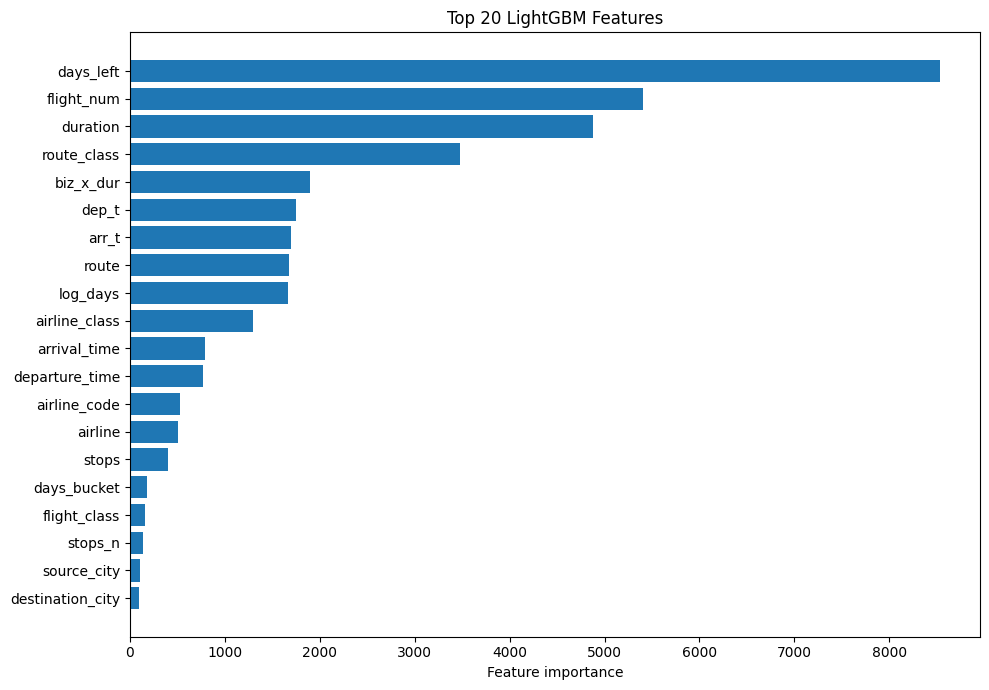

In [16]:
importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": final_model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance.head(20))

import matplotlib.pyplot as plt

top_features = importance.head(20).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature importance")
plt.title("Top 20 LightGBM Features")
plt.tight_layout()
plt.show()